<a href="https://colab.research.google.com/github/vandita1803/DAA-Lab/blob/main/HashTable.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import time
import statistics

class ChainingHashTable:
    def __init__(self, size):
        self.size = size
        self.table = [[] for _ in range(size)]

    def insert(self, key):
        index = key % self.size
        if key not in self.table[index]:
            self.table[index].append(key)

    def search(self, key):
        index = key % self.size
        return key in self.table[index]


class LinearProbingHashTable:
    def __init__(self, size):
        self.size = size
        self.table = [None] * size

    def insert(self, key):
        index = key % self.size

        for _ in range(self.size):
            if self.table[index] == key:
                return
            if self.table[index] is None:
                self.table[index] = key
                return
            index = (index + 1) % self.size

        raise OverflowError("Hash table is full")

    def search(self, key):
        index = key % self.size

        for _ in range(self.size):
            if self.table[index] is None:
                return False
            if self.table[index] == key:
                return True
            index = (index + 1) % self.size

        return False


sizes = list(range(100, 5001, 250))
chaining_times = []
probing_times = []
runs = 5

for n in sizes:
    keys = [i for i in range(n)]
    measurements_chaining = []
    measurements_probing = []

    for _ in range(runs):
        chaining = ChainingHashTable(n)
        start = time.perf_counter_ns()
        for key in keys:
            chaining.insert(key)
        for key in keys:
            chaining.search(key)
        end = time.perf_counter_ns()
        measurements_chaining.append(end - start)

        probing = LinearProbingHashTable(2 * n)
        start = time.perf_counter_ns()
        for key in keys:
            probing.insert(key)
        for key in keys:
            probing.search(key)
        end = time.perf_counter_ns()
        measurements_probing.append(end - start)

    chaining_times.append(statistics.median(measurements_chaining))
    probing_times.append(statistics.median(measurements_probing))


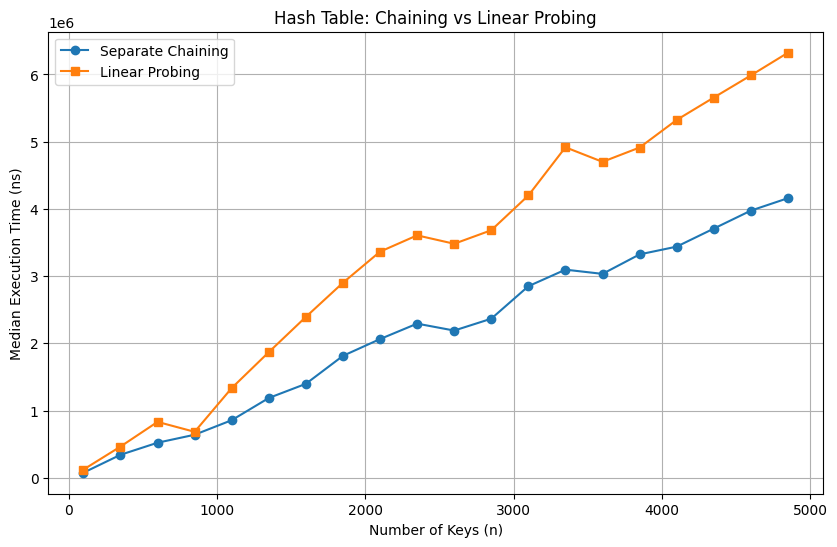

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(sizes, chaining_times, marker='o', label='Separate Chaining')
plt.plot(sizes, probing_times, marker='s', label='Linear Probing')
plt.title("Hash Table: Chaining vs Linear Probing")
plt.xlabel("Number of Keys (n)")
plt.ylabel("Median Execution Time (ns)")
plt.legend()
plt.grid(True)
plt.show()
